# Symbolic Regression for Reaction-Rate Equation Discovery

This notebook compares preprocessing and symbolic-regression methods using six benchmark rate laws and multiple initial concentrations. Training, validation, and final testing are separated by initial concentration to assess generalization beyond the concentration range used for fitting.

## 1. Environment Setup

Install the packages in the active Jupyter environment if they are not already available.

```python
%pip install pysr numpy pandas matplotlib scipy sympy scikit-learn
```

The smoothing-spline GCV implementation uses `scipy.interpolate.make_smoothing_spline`, available in SciPy 1.10 and later. PySR also requires its Julia backend, which is initialized on first use.

## 2. Import Libraries

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sympy as sp

from itertools import combinations
from pathlib import Path
from scipy.signal import savgol_filter
from scipy.interpolate import make_smoothing_spline
from sklearn.metrics import mean_squared_error, mean_absolute_error
from pysr import PySRRegressor

pd.set_option("display.max_colwidth", 120)

## 3. Load and Normalize the Generated Dataset

In [2]:
data_dir_candidates = [
    Path("reaction_data"),
    Path("reaction_data_generated"),
    Path("../reaction_data"),
    Path("../reaction_data_generated")
]

data_dir = next(
    (
        candidate for candidate in data_dir_candidates
        if (candidate / "reaction_dataset.csv").exists()
        and (candidate / "rate_law_parameters.csv").exists()
    ),
    None
)

if data_dir is None:
    searched_paths = [str(path.resolve()) for path in data_dir_candidates]
    raise FileNotFoundError(
        "Could not find reaction_dataset.csv and rate_law_parameters.csv. "
        f"Searched: {searched_paths}"
    )

df = pd.read_csv(data_dir / "reaction_dataset.csv")
parameters_df = pd.read_csv(data_dir / "rate_law_parameters.csv")

TRAIN_INITIAL_CONCENTRATIONS = [0.025, 0.05]
HELD_OUT_INITIAL_CONCENTRATION = 0.075

reaction_id_map = {
    "first_order": "First_Order",
    "second_order": "Second_Order",
    "fractional_order_1_5": "Fractional_Order",
    "saturation": "Saturation",
    "fourth_order": "Fourth_Order",
    "zero_order": "Zero_Order"
}

reaction_name_map = {
    "First order": "First_Order",
    "Second order": "Second_Order",
    "Fractional order (1.5)": "Fractional_Order",
    "Saturation kinetics": "Saturation",
    "Fourth order": "Fourth_Order",
    "Zero order": "Zero_Order"
}

column_aliases = {
    "CA_true_mol_L": "CA_true",
    "CA_observed_mol_L": "CA_observed",
    "noise_level_pct_of_CA0": "noise_level",
    "replicate_id": "replicate"
}

df = df.rename(columns=column_aliases)

if "reaction" not in df.columns:
    if "rate_law_id" in df.columns:
        df["reaction"] = df["rate_law_id"].map(reaction_id_map)
    elif "rate_law_name" in df.columns:
        df["reaction"] = df["rate_law_name"].map(reaction_name_map)

if "reaction" in df.columns:
    df["reaction"] = df["reaction"].replace(reaction_name_map)

required_columns = {
    "reaction", "time_min", "noise_level", "replicate",
    "initial_concentration_mol_L", "CA_true", "CA_observed"
}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(f"Missing dataset columns: {sorted(missing_columns)}")

if df["reaction"].isna().any():
    raise ValueError("Some reaction identifiers could not be mapped.")

if df["noise_level"].max() > 1:
    df["noise_level"] = df["noise_level"] / 100.0

parameter_aliases = {
    "Vmax_mol_L_min": "Vmax",
    "K_mol_L": "K"
}
parameters_df = parameters_df.rename(columns=parameter_aliases)

if "reaction" not in parameters_df.columns:
    if "rate_law_id" in parameters_df.columns:
        parameters_df["reaction"] = parameters_df["rate_law_id"].map(reaction_id_map)
    elif "rate_law_name" in parameters_df.columns:
        parameters_df["reaction"] = parameters_df["rate_law_name"].map(reaction_name_map)

if "reaction" in parameters_df.columns:
    parameters_df["reaction"] = parameters_df["reaction"].replace(reaction_name_map)

for parameter in ["k", "Vmax", "K"]:
    if parameter not in parameters_df.columns:
        parameters_df[parameter] = np.nan

parameters_df = parameters_df.drop_duplicates("reaction").reset_index(drop=True)
parameter_lookup = parameters_df.set_index("reaction")[["k", "Vmax", "K"]].to_dict("index")

print("Dataset path:", (data_dir / "reaction_dataset.csv").resolve())
print("Dataset shape:", df.shape)
print("Reactions:", sorted(df["reaction"].unique()))
print("Noise levels:", sorted(df["noise_level"].unique()))
print("Initial concentrations:", sorted(df["initial_concentration_mol_L"].unique()))
print("Training initial concentrations:", TRAIN_INITIAL_CONCENTRATIONS)
print("Held-out initial concentration:", HELD_OUT_INITIAL_CONCENTRATION)
print("Replicates:", sorted(df["replicate"].unique()))
print("Missing values:", int(df[list(required_columns)].isna().sum().sum()))

display(df.head())
display(parameters_df[["reaction", "k", "Vmax", "K"]])

Dataset path: C:\F\CHE657 Term Project\reaction_data\reaction_dataset.csv
Dataset shape: (34848, 7)
Reactions: ['First_Order', 'Fourth_Order', 'Fractional_Order', 'Saturation', 'Second_Order', 'Zero_Order']
Noise levels: [np.float64(0.0), np.float64(0.01), np.float64(0.03), np.float64(0.05)]
Initial concentrations: [np.float64(0.025), np.float64(0.05), np.float64(0.075)]
Training initial concentrations: [0.025, 0.05]
Held-out initial concentration: 0.075
Replicates: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Missing values: 0


,reaction,time_min,noise_level,replicate,initial_concentration_mol_L,CA_true,CA_observed
0,First_Order,0.00,0.0,0,0.025,0.025000,0.025000
1,First_Order,0.25,0.0,0,0.025,0.024383,0.024383
2,First_Order,0.50,0.0,0,0.025,0.023781,0.023781
3,First_Order,0.75,0.0,0,0.025,0.023194,0.023194
4,First_Order,1.00,0.0,0,0.025,0.022621,0.022621


,reaction,k,Vmax,K
0,First_Order,0.100000,NaN,NaN
1,Second_Order,2.000000,NaN,NaN
2,Fractional_Order,0.447214,NaN,NaN
3,Saturation,NaN,0.007,0.02
4,Fourth_Order,800.000000,NaN,NaN
5,Zero_Order,0.005000,NaN,NaN


## 4. Define the Benchmark Rate Laws

The target is the disappearance rate of reactant A:

\[
r=-r_A=-\frac{dC_A}{dt}.
\]

The six benchmark expressions are:

| Reaction | Rate law |
|---|---|
| First order | \(r=kC_A\) |
| Second order | \(r=kC_A^2\) |
| Fractional order | \(r=kC_A^{1.5}\) |
| Saturation | \(r=V_{\max}C_A/(K+C_A)\) |
| Fourth order | \(r=kC_A^4\) |
| Zero order | \(r=k\) |

The numerical parameters and units are stored in `rate_law_parameters.csv`.

In [3]:
def calculate_rate(CA, reaction, params):
    if reaction == "First_Order":
        return params["k"] * CA
    if reaction == "Second_Order":
        return params["k"] * CA**2
    if reaction == "Fractional_Order":
        return params["k"] * CA**1.5
    if reaction == "Saturation":
        return params["Vmax"] * CA / (params["K"] + CA)
    if reaction == "Fourth_Order":
        return params["k"] * CA**4
    if reaction == "Zero_Order":
        return params["k"]
    raise ValueError(f"Unknown reaction: {reaction}")


def calculate_rate_array(concentrations, reaction, params):
    return np.asarray(
        [calculate_rate(value, reaction, params) for value in concentrations],
        dtype=float
    )

## 5. Construct the Clean Ground-Truth Dataset

The clean-data baseline uses only the two training initial concentrations. The held-out initial concentration is reserved for the final noisy-data test.

In [4]:
df_clean = df.loc[
    (df["noise_level"] == 0)
    & df["initial_concentration_mol_L"].isin(TRAIN_INITIAL_CONCENTRATIONS)
].copy()

df_clean["rate_true"] = [
    calculate_rate(value, reaction, parameter_lookup[reaction])
    for value, reaction in zip(df_clean["CA_true"], df_clean["reaction"])
]

zero_order_mask = df_clean["reaction"] == "Zero_Order"
zero_order_scale = df_clean.loc[zero_order_mask, "CA_true"].abs().max()
depletion_tolerance = 1e-8 * zero_order_scale

df_clean = df_clean.loc[
    ~(
        zero_order_mask
        & (df_clean["CA_true"] <= depletion_tolerance)
    )
].copy()

df_clean = df_clean.sort_values(
    ["reaction", "initial_concentration_mol_L", "time_min"]
).reset_index(drop=True)

print("Clean dataset shape:", df_clean.shape)
display(df_clean.groupby("reaction").size().rename("observations"))
display(df_clean.head())

Clean dataset shape: (1270, 8)


reaction
First_Order         242
Fourth_Order        242
Fractional_Order    242
Saturation          242
Second_Order        242
Zero_Order           60
Name: observations, dtype: int64

,reaction,time_min,noise_level,replicate,initial_concentration_mol_L,CA_true,CA_observed,rate_true
0,First_Order,0.00,0.0,0,0.025,0.025000,0.025000,0.002500
1,First_Order,0.25,0.0,0,0.025,0.024383,0.024383,0.002438
2,First_Order,0.50,0.0,0,0.025,0.023781,0.023781,0.002378
3,First_Order,0.75,0.0,0,0.025,0.023194,0.023194,0.002319
4,First_Order,1.00,0.0,0,0.025,0.022621,0.022621,0.002262


## 6. Visualize the Ground-Truth Rate Laws

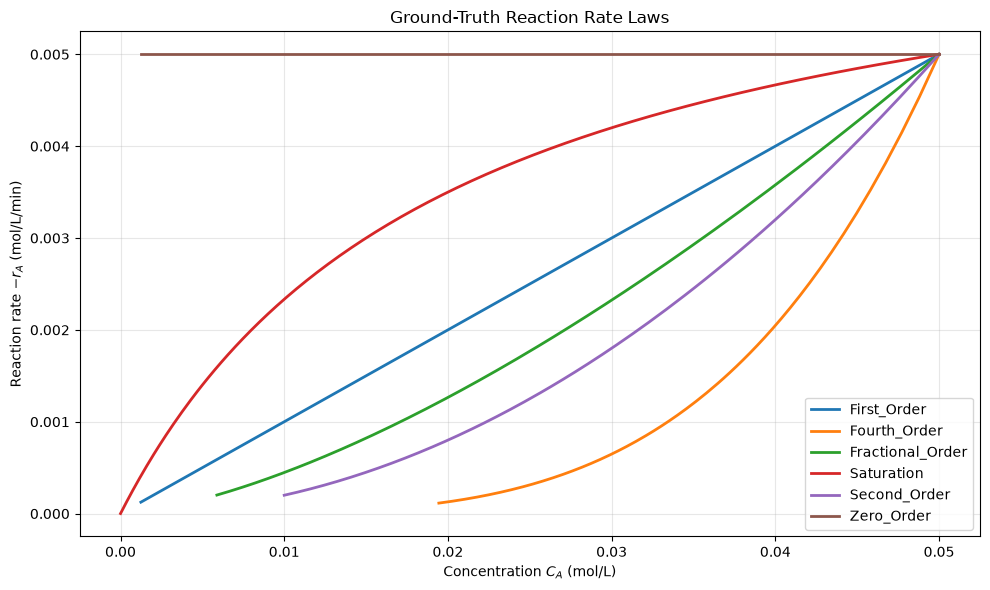

In [5]:
plt.figure(figsize=(10, 6))

for reaction, subset in df_clean.groupby("reaction"):
    subset = subset.sort_values("CA_true")
    plt.plot(
        subset["CA_true"],
        subset["rate_true"],
        label=reaction,
        linewidth=2
    )

plt.xlabel("Concentration $C_A$ (mol/L)")
plt.ylabel("Reaction rate $-r_A$ (mol/L/min)")
plt.title("Ground-Truth Reaction Rate Laws")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Configure PySR

A separate symbolic-regression model is trained for each benchmark reaction. The same configuration is used across reactions so their clean-data results are comparable.

In [6]:
def create_pysr_model(verbosity=0):
    return PySRRegressor(
        niterations=100,
        populations=15,
        population_size=33,
        maxsize=20,
        binary_operators=["+", "-", "*", "/", "^"],
        constraints={"^": (-1, 1)},
        model_selection="best",
        verbosity=verbosity
    )

## 8. Run the Clean-Data PySR Baseline

For each reaction, PySR receives clean concentration and exact rate data from the training initial concentrations only. This establishes an ideal-condition reference and does not use the held-out initial concentration.

In [7]:
clean_models = {}

for reaction, subset in df_clean.groupby("reaction"):
    X = subset[["CA_true"]].to_numpy(dtype=float)
    y = subset["rate_true"].to_numpy(dtype=float)

    model = create_pysr_model(verbosity=0)
    model.fit(X, y)
    clean_models[reaction] = model

    print(f"Completed: {reaction}")

Completed: First_Order
Completed: Fourth_Order
Completed: Fractional_Order
Completed: Saturation
Completed: Second_Order
Completed: Zero_Order


## 9. Summarize the Clean-Data PySR Equations

In [8]:
baseline_results = []

for reaction, model in clean_models.items():
    equations = model.equations_
    best = equations.loc[equations["loss"].idxmin()]

    baseline_results.append({
        "Reaction": reaction,
        "Lowest-loss equation": best["equation"],
        "PySR loss": best["loss"],
        "Complexity": best["complexity"],
        "Score": best["score"]
    })

baseline_df = pd.DataFrame(baseline_results)
display(baseline_df)

,Reaction,Lowest-loss equation,PySR loss,Complexity,Score
0,First_Order,x0 * ((x0 / (x0 * 0.1)) * 0.010000001),3.727645e-21,9,0.081582
1,Fourth_Order,(x0 * ((x0 * x0) * 761.37604)) * (x0 * 1.0507292),8.360294e-21,11,0.098312
2,Fractional_Order,((x0 * x0) ^ 0.75091505) / ((((x0 + -0.010307282) + -0.010307282) * x0) + 2.2218325),7.509492e-13,15,0.046950
3,Saturation,0.03700742 - (x0 * (((x0 ^ x0) * (0.07408983 / ((x0 + x0) / (x0 ^ x0)))) - -0.092050895)),8.710869e-10,19,0.169759
4,Second_Order,(x0 + x0) / ((x0 / x0) / x0),4.179162e-21,9,0.118428
5,Zero_Order,0.005,0.000000e+00,1,0.000000


## 10. Equation Simplification

The simplifier generates candidate expressions from algebraic transformations, additive-term subsets, and numerator or denominator subsets of rational expressions. It then refits **multiplicative coefficients only**.

Powers, exponents, and other nonlinear structure are held fixed during coefficient fitting. This prevents the simplification stage from silently changing a candidate's reaction order.

The ranking score combines a BIC-style residual term with an explicit symbolic-complexity penalty. It is a heuristic screening score, not formal BIC. A selected equation must still be tested on independent trajectories.

### 10.1 Define the Candidate-Generation and Fitting Functions

In [9]:
x0 = sp.symbols("x0")


def subset_expressions(terms, max_terms=5):
    terms = list(terms)
    if not terms:
        return []
    if len(terms) > max_terms:
        return [sp.Add(*terms)] + terms
    return [
        sp.Add(*subset)
        for size in range(1, len(terms) + 1)
        for subset in combinations(terms, size)
    ]


def evaluate_expression(expression, X):
    function = sp.lambdify(x0, expression, modules="numpy")
    with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
        values = np.asarray(function(X))
    if np.iscomplexobj(values):
        raise ValueError("Expression produced complex values.")
    values = np.asarray(values, dtype=float)
    return np.broadcast_to(values, X.shape)


def fit_candidate_coefficients(candidate, X, y):
    expanded = sp.expand(candidate)
    terms = sp.Add.make_args(expanded)
    bases = [term.as_coeff_Mul()[1] for term in terms]

    columns = [evaluate_expression(base, X) for base in bases]
    design_matrix = np.column_stack(columns)

    if not np.all(np.isfinite(design_matrix)):
        return None

    coefficients, _, rank, _ = np.linalg.lstsq(
        design_matrix, y, rcond=None
    )

    predictions = design_matrix @ coefficients
    if not np.all(np.isfinite(predictions)):
        return None

    fitted_expression = sp.simplify(
        sum(
            sp.Float(float(coefficient), 12) * base
            for coefficient, base in zip(coefficients, bases)
        )
    )

    rss = float(np.sum((y - predictions) ** 2))
    complexity = int(sp.count_ops(fitted_expression))
    return fitted_expression, rss, int(rank), complexity


def automatic_simplify(
    equation,
    X,
    y,
    max_terms=5,
    complexity_weight=1.0
):
    X = np.asarray(X, dtype=float).reshape(-1)
    y = np.asarray(y, dtype=float).reshape(-1)

    if X.shape != y.shape:
        raise ValueError("X and y must have the same number of observations.")
    if X.size == 0:
        raise ValueError("X and y cannot be empty.")
    if not np.all(np.isfinite(X)) or not np.all(np.isfinite(y)):
        raise ValueError("X and y must contain only finite values.")

    expression = sp.sympify(equation)
    candidates = {}

    def add_candidate(candidate):
        try:
            candidate = sp.cancel(candidate)
            if candidate not in (sp.nan, sp.zoo, sp.oo, -sp.oo):
                candidates[sp.srepr(candidate)] = candidate
        except (sp.SympifyError, ValueError, TypeError):
            return

    algebraic_forms = [
        expression,
        sp.simplify(expression),
        sp.factor(expression),
        sp.cancel(expression),
        sp.together(expression),
        sp.expand(expression)
    ]

    for form in algebraic_forms:
        add_candidate(form)

    expanded_expression = sp.expand(expression)
    additive_terms = sp.Add.make_args(expanded_expression)

    for candidate in subset_expressions(additive_terms, max_terms):
        add_candidate(candidate)

    numerator, denominator = sp.fraction(sp.together(expression))
    numerator_terms = sp.Add.make_args(sp.expand(numerator))
    denominator_terms = sp.Add.make_args(sp.expand(denominator))

    numerator_candidates = subset_expressions(numerator_terms, max_terms)
    denominator_candidates = subset_expressions(denominator_terms, max_terms)

    for numerator_candidate in numerator_candidates:
        add_candidate(numerator_candidate / denominator)

    for denominator_candidate in denominator_candidates:
        if denominator_candidate != 0:
            add_candidate(numerator / denominator_candidate)

    if len(numerator_terms) <= 3 and len(denominator_terms) <= 3:
        for numerator_candidate in numerator_candidates:
            for denominator_candidate in denominator_candidates:
                if denominator_candidate != 0:
                    add_candidate(numerator_candidate / denominator_candidate)

    n = len(y)
    signal_scale = max(float(np.mean(y**2)), np.finfo(float).tiny)
    residual_floor = np.finfo(float).eps * signal_scale
    results = []

    for candidate in candidates.values():
        try:
            fitted = fit_candidate_coefficients(candidate, X, y)
            if fitted is None:
                continue

            fitted_expression, rss, parameter_count, complexity = fitted
            rss_per_observation = max(rss / n, residual_floor)
            bic_style = (
                n * np.log(rss_per_observation)
                + parameter_count * np.log(n)
            )
            selection_score = (
                bic_style
                + complexity_weight * complexity * np.log(n)
            )

            results.append({
                "equation": fitted_expression,
                "terms": len(sp.Add.make_args(sp.expand(fitted_expression))),
                "complexity": complexity,
                "RSS": rss,
                "BIC-style score": bic_style,
                "Selection Score": selection_score
            })

        except (
            ValueError, TypeError, OverflowError,
            ZeroDivisionError, FloatingPointError
        ):
            continue

    if not results:
        raise ValueError("No valid candidate equations were generated.")

    results_df = pd.DataFrame(results)
    results_df["equation_key"] = results_df["equation"].map(sp.srepr)
    results_df = results_df.drop_duplicates("equation_key")
    results_df = results_df.drop(columns="equation_key")
    results_df = results_df.sort_values(
        ["Selection Score", "complexity", "RSS"]
    ).reset_index(drop=True)

    return results_df.iloc[0], results_df

### 10.2 Simplify the Complete Clean-Data PySR Libraries

In [10]:
def simplify_pysr_library(model, X, y):
    summaries = []
    candidate_tables = {}

    for equation_index, row in model.equations_.iterrows():
        best, candidates = automatic_simplify(
            row["sympy_format"], X, y
        )
        candidate_tables[equation_index] = candidates

        summaries.append({
            "Source equation": row["sympy_format"],
            "Source complexity": row["complexity"],
            "Simplified equation": best["equation"],
            "Terms": best["terms"],
            "Complexity": best["complexity"],
            "RSS": best["RSS"],
            "BIC-style score": best["BIC-style score"],
            "Selection Score": best["Selection Score"]
        })

    summary_df = pd.DataFrame(summaries).sort_values(
        ["Selection Score", "Complexity", "RSS"]
    ).reset_index(drop=True)

    return summary_df.iloc[0], summary_df, candidate_tables


automatic_results = []
all_candidates = {}

for reaction, model in clean_models.items():
    subset = df_clean.loc[df_clean["reaction"] == reaction]
    X = subset["CA_true"].to_numpy(dtype=float)
    y = subset["rate_true"].to_numpy(dtype=float)

    lowest_loss = model.equations_.loc[
        model.equations_["loss"].idxmin(), "sympy_format"
    ]

    best, summary, candidate_tables = simplify_pysr_library(
        model, X, y
    )

    all_candidates[reaction] = candidate_tables

    automatic_results.append({
        "Reaction": reaction,
        "PySR lowest-loss equation": lowest_loss,
        "Simplifier source equation": best["Source equation"],
        "Simplified equation": best["Simplified equation"],
        "Complexity": best["Complexity"],
        "RSS": best["RSS"],
        "Selection Score": best["Selection Score"]
    })

automatic_df = pd.DataFrame(automatic_results)
display(automatic_df)

,Reaction,PySR lowest-loss equation,Simplifier source equation,Simplified equation,Complexity,RSS,Selection Score
0,First_Order,x0*x0*0.010000001/(x0*0.1),x0*0.1,0.1*x0,1,4.587220e-35,-11819.873314
1,Fourth_Order,x0*x0*x0*761.37604*x0*1.0507292,x0*x0*800.0*x0*x0,800.0*x0**4,2,5.194032e-36,-12080.159258
2,Fractional_Order,(x0*x0)**0.75091505/(x0*(x0 - 0.010307282 - 0.010307282) + 2.2218325),(x0*x0)**0.75039685/2.2311807,0.448444907945*(x0**2)**0.75039685,3,5.413846e-11,-7027.120425
3,Saturation,0.03700742 - x0*(x0**x0*0.07408983/((x0 + x0)/(x0**x0)) - 1*(-0.092050895)),0.03700742 - x0*(x0**x0*0.07408983/((x0 + x0)/(x0**x0)) - 1*(-0.092050895)),-0.091642971502*x0 - 0.0369777407609*x0**(2*x0) + 0.0369408131882,6,2.106263e-07,-4999.232147
4,Second_Order,(x0 + x0)/((x0/(x0*x0))),x0*(x0 + x0),2.0*x0**2,2,1.756776e-35,-11939.813589
5,Zero_Order,0.00500000000000000,0.00500000000000000,0.00500000000000,0,4.513898e-35,-2794.322943


### 10.3 Compare Original and Simplified Clean-Data Equations

The following comparison is in-sample because the clean trajectories were used to fit the candidate equations. It is an implementation check for the simplifier, not evidence of generalization.

In [11]:
def predict_expression(expression, X):
    function = sp.lambdify(x0, sp.sympify(expression), modules="numpy")
    with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
        predictions = np.asarray(function(X))
    if np.iscomplexobj(predictions):
        raise ValueError("Expression produced complex predictions.")
    return np.broadcast_to(
        np.asarray(predictions, dtype=float),
        np.shape(X)
    )


comparison_results = []

for _, row in automatic_df.iterrows():
    reaction = row["Reaction"]
    subset = df_clean.loc[df_clean["reaction"] == reaction]
    X = subset["CA_true"].to_numpy(dtype=float)
    y = subset["rate_true"].to_numpy(dtype=float)

    original_predictions = predict_expression(
        row["PySR lowest-loss equation"], X
    )
    simplified_predictions = predict_expression(
        row["Simplified equation"], X
    )

    comparison_results.append({
        "Reaction": reaction,
        "Original RMSE": np.sqrt(mean_squared_error(y, original_predictions)),
        "Simplified RMSE": np.sqrt(mean_squared_error(y, simplified_predictions)),
        "Original MAE": mean_absolute_error(y, original_predictions),
        "Simplified MAE": mean_absolute_error(y, simplified_predictions)
    })

automatic_comparison_df = pd.DataFrame(comparison_results)
display(automatic_comparison_df)

,Reaction,Original RMSE,Simplified RMSE,Original MAE,Simplified MAE
0,First_Order,1.625271e-10,1.796182e-18,1.194279e-10,1.317395e-18
1,Fourth_Order,4.388580e-11,1.587191e-19,2.555540e-11,8.265922e-20
2,Fractional_Order,8.665601e-07,4.729827e-07,8.408681e-07,4.254950e-07
3,Saturation,2.951439e-05,2.950181e-05,2.609887e-05,2.610792e-05
4,Second_Order,4.086241e-20,0.000000e+00,1.008039e-20,0.000000e+00
5,Zero_Order,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00


## 11. Noise-Reduction Methods

Only measured concentration and time values enter the preprocessing functions. Clean simulated concentrations and exact rates are joined back later, exclusively for retrospective evaluation.

Three methods are compared:

1. Raw numerical differentiation.
2. Fixed-window Savitzky–Golay smoothing and differentiation.
3. Smoothing-spline fitting with the smoothing parameter selected by generalized cross-validation (GCV).

GCV selects the spline regularization parameter from the noisy trajectory. It does not use the clean reference data.

### 11.1 Define the Preprocessing Settings

In [12]:
SG_WINDOW = 11
SG_POLYORDER = 3
EDGE_TRIM = SG_WINDOW // 2

if SG_WINDOW % 2 == 0:
    raise ValueError("SG_WINDOW must be odd.")
if SG_POLYORDER >= SG_WINDOW:
    raise ValueError("SG_POLYORDER must be smaller than SG_WINDOW.")

### 11.2 Define the Raw, Savitzky–Golay, and Smoothing-Spline Methods

The smoothing spline uses `lam=None`, which selects its smoothing parameter by GCV. Its derivative is evaluated analytically from the fitted spline.

In [13]:
def preprocess_trajectory(group):
    group = group.sort_values("time_min").copy()

    time = group["time_min"].to_numpy(dtype=float)
    concentration = group["CA_observed"].to_numpy(dtype=float)

    if len(group) <= SG_WINDOW:
        raise ValueError("Trajectory is too short for the selected SG window.")

    time_steps = np.diff(time)
    if not np.allclose(time_steps, time_steps[0]):
        raise ValueError("The current SG implementation requires equally spaced time points.")

    dt = time_steps[0]

    rate_raw = -np.gradient(
        concentration, time, edge_order=2
    )

    concentration_sg = savgol_filter(
        concentration,
        window_length=SG_WINDOW,
        polyorder=SG_POLYORDER
    )

    rate_sg = -savgol_filter(
        concentration,
        window_length=SG_WINDOW,
        polyorder=SG_POLYORDER,
        deriv=1,
        delta=dt
    )

    spline = make_smoothing_spline(
        time,
        concentration,
        lam=None
    )

    concentration_spline = spline(time)
    rate_spline = -spline.derivative()(time)

    group["rate_raw"] = rate_raw
    group["CA_sg"] = concentration_sg
    group["rate_sg"] = rate_sg
    group["CA_spline"] = concentration_spline
    group["rate_spline"] = rate_spline

    group["valid_interior"] = (
        (np.arange(len(group)) >= EDGE_TRIM)
        & (np.arange(len(group)) < len(group) - EDGE_TRIM)
    )

    return group

### 11.3 Preprocess All Noisy Trajectories

This cell passes only reaction identifiers, time, noise/replicate identifiers, and observed concentrations to the preprocessing functions. It does not pass `CA_true` or the theoretical rate.

In [14]:
observed_columns = [
    "reaction", "initial_concentration_mol_L", "time_min",
    "noise_level", "replicate", "CA_observed"
]

observed_data = df.loc[
    df["noise_level"] > 0,
    observed_columns
].copy()

processed_groups = []

group_columns = ["reaction", "initial_concentration_mol_L", "noise_level", "replicate"]

for _, group in observed_data.groupby(group_columns, sort=False):
    processed_groups.append(preprocess_trajectory(group))

df_processed = pd.concat(
    processed_groups,
    ignore_index=True
)

df_processed = df_processed.sort_values(
    group_columns + ["time_min"]
).reset_index(drop=True)

print("Processed dataset shape:", df_processed.shape)
print("Reactions:", sorted(df_processed["reaction"].unique()))
print("Noise levels:", sorted(df_processed["noise_level"].unique()))
print("Replicates:", sorted(df_processed["replicate"].unique()))
print("Missing values:")
display(df_processed.isna().sum())
display(df_processed.head())

Processed dataset shape: (32670, 12)
Reactions: ['First_Order', 'Fourth_Order', 'Fractional_Order', 'Saturation', 'Second_Order', 'Zero_Order']
Noise levels: [np.float64(0.01), np.float64(0.03), np.float64(0.05)]
Replicates: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Missing values:


reaction                       0
initial_concentration_mol_L    0
time_min                       0
noise_level                    0
replicate                      0
CA_observed                    0
rate_raw                       0
CA_sg                          0
rate_sg                        0
CA_spline                      0
rate_spline                    0
valid_interior                 0
dtype: int64

,reaction,initial_concentration_mol_L,time_min,noise_level,replicate,CA_observed,rate_raw,CA_sg,rate_sg,CA_spline,rate_spline,valid_interior
0,First_Order,0.025,0.00,0.01,1,0.024591,-0.000794,0.024723,0.001222,0.024834,0.002166,False
1,First_Order,0.025,0.25,0.01,1,0.024539,0.001210,0.024358,0.001674,0.024292,0.002169,False
2,First_Order,0.025,0.50,0.01,1,0.023986,0.002708,0.023894,0.002024,0.023749,0.002174,False
3,First_Order,0.025,0.75,0.01,1,0.023185,0.001955,0.023355,0.002273,0.023205,0.002176,False
4,First_Order,0.025,1.00,0.01,1,0.023009,0.002784,0.022766,0.002419,0.022661,0.002174,False


## 12. Retrospective Evaluation of Rate Estimates

The clean concentration and exact kinetic rate are joined to the processed data only after preprocessing is complete. They are used exclusively to score the methods.

The first and last `EDGE_TRIM` observations of every trajectory are excluded from all three methods so the comparison uses the same interior time points. For zero-order kinetics, observations near and after depletion are excluded from the evaluation because the zero-order law is not valid after A is exhausted. This depletion mask uses ground truth only for retrospective scoring; a real-data implementation will need a measurement-based depletion detector or a piecewise kinetic model.

### 12.1 Attach Ground-Truth Reference Values for Evaluation

In [15]:
reference_columns = [
    "reaction", "initial_concentration_mol_L", "time_min",
    "noise_level", "replicate", "CA_true"
]

truth_reference = df.loc[
    (df["noise_level"] > 0)
    & df["initial_concentration_mol_L"].isin(TRAIN_INITIAL_CONCENTRATIONS),
    reference_columns
].copy()

evaluation_data = df_processed.loc[
    df_processed["initial_concentration_mol_L"].isin(TRAIN_INITIAL_CONCENTRATIONS)
].copy()

df_evaluation = evaluation_data.merge(
    truth_reference,
    on=["reaction", "initial_concentration_mol_L", "time_min", "noise_level", "replicate"],
    how="left",
    validate="one_to_one"
)

df_evaluation["rate_true"] = [
    calculate_rate(value, reaction, parameter_lookup[reaction])
    for value, reaction in zip(
        df_evaluation["CA_true"],
        df_evaluation["reaction"]
    )
]

evaluation_groups = []

for _, group in df_evaluation.groupby(
    ["reaction", "initial_concentration_mol_L", "noise_level", "replicate"],
    sort=False
):
    group = group.sort_values("time_min").copy()
    indices = np.arange(len(group))

    valid = (
        (indices >= EDGE_TRIM)
        & (indices < len(group) - EDGE_TRIM)
    )

    reaction = group["reaction"].iloc[0]

    if reaction == "Zero_Order":
        true_concentration = group["CA_true"].to_numpy(dtype=float)
        depletion_tolerance = 1e-8 * np.max(np.abs(true_concentration))
        active_indices = np.flatnonzero(
            true_concentration > depletion_tolerance
        )

        if active_indices.size == 0:
            continue

        last_active = active_indices[-1]
        valid &= indices <= last_active - EDGE_TRIM
        valid &= true_concentration > depletion_tolerance

    group["evaluation_valid"] = valid
    evaluation_groups.append(group)

df_evaluation = pd.concat(
    evaluation_groups,
    ignore_index=True
)

print("Evaluation dataset shape:", df_evaluation.shape)
print("Evaluation observations:", int(df_evaluation["evaluation_valid"].sum()))

Evaluation dataset shape: (21780, 15)
Evaluation observations: 17250


### 12.2 Calculate Metrics for Every Trajectory

In [16]:
method_columns = {
    "Raw differentiation": "rate_raw",
    "Savitzky-Golay": "rate_sg",
    "Smoothing spline GCV": "rate_spline"
}

trajectory_metrics = []

for (reaction, initial_concentration, noise, replicate), group in df_evaluation.groupby(
    ["reaction", "initial_concentration_mol_L", "noise_level", "replicate"],
    sort=False
):
    valid = group["evaluation_valid"].to_numpy(dtype=bool)

    if not valid.any():
        continue

    y_true = group.loc[valid, "rate_true"].to_numpy(dtype=float)

    for method, rate_column in method_columns.items():
        y_estimated = group.loc[valid, rate_column].to_numpy(dtype=float)
        error = y_estimated - y_true

        trajectory_metrics.append({
            "Reaction": reaction,
            "Initial concentration": initial_concentration,
            "Noise": noise,
            "Replicate": replicate,
            "Method": method,
            "Observations": int(valid.sum()),
            "RMSE": np.sqrt(np.mean(error**2)),
            "MAE": np.mean(np.abs(error)),
            "Bias": np.mean(error)
        })

rate_metrics_df = pd.DataFrame(trajectory_metrics)
display(rate_metrics_df)

,Reaction,Initial concentration,Noise,Replicate,Method,Observations,RMSE,MAE,Bias
0,First_Order,0.025,0.01,1,Raw differentiation,111,0.000593,0.000481,3.259746e-06
1,First_Order,0.025,0.01,1,Savitzky-Golay,111,0.000245,0.000189,7.338984e-06
2,First_Order,0.025,0.01,1,Smoothing spline GCV,111,0.000045,0.000037,3.111672e-06
3,First_Order,0.025,0.01,2,Raw differentiation,111,0.000718,0.000591,-9.879679e-07
4,First_Order,0.025,0.01,2,Savitzky-Golay,111,0.000260,0.000205,5.121257e-06
...,...,...,...,...,...,...,...,...,...
535,Zero_Order,0.050,0.05,4,Savitzky-Golay,30,0.002713,0.002191,-5.532202e-04
536,Zero_Order,0.050,0.05,4,Smoothing spline GCV,30,0.000390,0.000299,-2.988239e-04
537,Zero_Order,0.050,0.05,5,Raw differentiation,30,0.006647,0.005176,4.355024e-04
538,Zero_Order,0.050,0.05,5,Savitzky-Golay,30,0.001977,0.001623,3.884980e-04


### 12.3 Summarize Performance by Reaction, Initial Concentration, and Noise Level

The summary reports performance separately for each initial concentration and noise condition.

In [17]:
rate_summary = (
    rate_metrics_df
    .groupby(["Reaction", "Initial concentration", "Noise", "Method"])
    .agg(
        Mean_RMSE=("RMSE", "mean"),
        SD_RMSE=("RMSE", "std"),
        Mean_MAE=("MAE", "mean"),
        Mean_Bias=("Bias", "mean")
    )
    .reset_index()
)

display(
    rate_summary.sort_values(
        ["Reaction", "Noise", "Method"]
    )
)

,Reaction,Initial concentration,Noise,Method,Mean_RMSE,SD_RMSE,Mean_MAE,Mean_Bias
0,First_Order,0.025,0.01,Raw differentiation,0.000680,0.000050,0.000548,-2.856698e-06
9,First_Order,0.050,0.01,Raw differentiation,0.001394,0.000098,0.001114,4.046600e-06
1,First_Order,0.025,0.01,Savitzky-Golay,0.000255,0.000014,0.000202,2.210133e-07
10,First_Order,0.050,0.01,Savitzky-Golay,0.000538,0.000040,0.000429,2.119537e-06
2,First_Order,0.025,0.01,Smoothing spline GCV,0.000039,0.000007,0.000032,-5.729612e-07
...,...,...,...,...,...,...,...,...
105,Zero_Order,0.050,0.05,Raw differentiation,0.007181,0.000369,0.005604,-9.095220e-05
97,Zero_Order,0.025,0.05,Savitzky-Golay,0.001122,0.000522,0.000959,1.247580e-04
106,Zero_Order,0.050,0.05,Savitzky-Golay,0.002271,0.000528,0.001872,-1.060905e-04
98,Zero_Order,0.025,0.05,Smoothing spline GCV,0.000353,0.000126,0.000319,1.963355e-04


### 12.4 Compare Methods Across the Five Smooth Kinetic Systems

Zero-order kinetics has a depletion discontinuity. It is summarized separately. Results are retained by initial concentration so performance at different training conditions remains visible.

In [18]:
smooth_reactions = [
    "First_Order",
    "Second_Order",
    "Fractional_Order",
    "Saturation",
    "Fourth_Order"
]

smooth_system_summary = (
    rate_metrics_df.loc[
        rate_metrics_df["Reaction"].isin(smooth_reactions)
    ]
    .groupby(["Initial concentration", "Noise", "Method"])
    .agg(
        Mean_RMSE=("RMSE", "mean"),
        SD_RMSE=("RMSE", "std")
    )
    .reset_index()
)

zero_order_summary = (
    rate_metrics_df.loc[
        rate_metrics_df["Reaction"] == "Zero_Order"
    ]
    .groupby(["Initial concentration", "Noise", "Method"])
    .agg(
        Mean_RMSE=("RMSE", "mean"),
        SD_RMSE=("RMSE", "std")
    )
    .reset_index()
)

print("Five continuously decaying kinetic systems")
display(smooth_system_summary)

print("Zero-order system")
display(zero_order_summary)

Five continuously decaying kinetic systems


,Initial concentration,Noise,Method,Mean_RMSE,SD_RMSE
0,0.025,0.01,Raw differentiation,0.000682,0.000050
1,0.025,0.01,Savitzky-Golay,0.000241,0.000021
2,0.025,0.01,Smoothing spline GCV,0.000034,0.000016
3,0.025,0.03,Raw differentiation,0.002082,0.000141
4,0.025,0.03,Savitzky-Golay,0.000714,0.000067
5,0.025,0.03,Smoothing spline GCV,0.000073,0.000030
6,0.025,0.05,Raw differentiation,0.003539,0.000351
7,0.025,0.05,Savitzky-Golay,0.001222,0.000147
8,0.025,0.05,Smoothing spline GCV,0.000110,0.000056
9,0.050,0.01,Raw differentiation,0.001411,0.000124


Zero-order system


,Initial concentration,Noise,Method,Mean_RMSE,SD_RMSE
0,0.025,0.01,Raw differentiation,0.000888,0.000081
1,0.025,0.01,Savitzky-Golay,0.000263,0.000076
2,0.025,0.01,Smoothing spline GCV,0.000190,0.000029
3,0.025,0.03,Raw differentiation,0.001915,0.000686
4,0.025,0.03,Savitzky-Golay,0.000699,0.000261
5,0.025,0.03,Smoothing spline GCV,0.000354,0.000205
6,0.025,0.05,Raw differentiation,0.002796,0.000782
7,0.025,0.05,Savitzky-Golay,0.001122,0.000522
8,0.025,0.05,Smoothing spline GCV,0.000353,0.000126
9,0.050,0.01,Raw differentiation,0.001385,0.000247


### 12.5 Visualize the Preprocessing Comparison

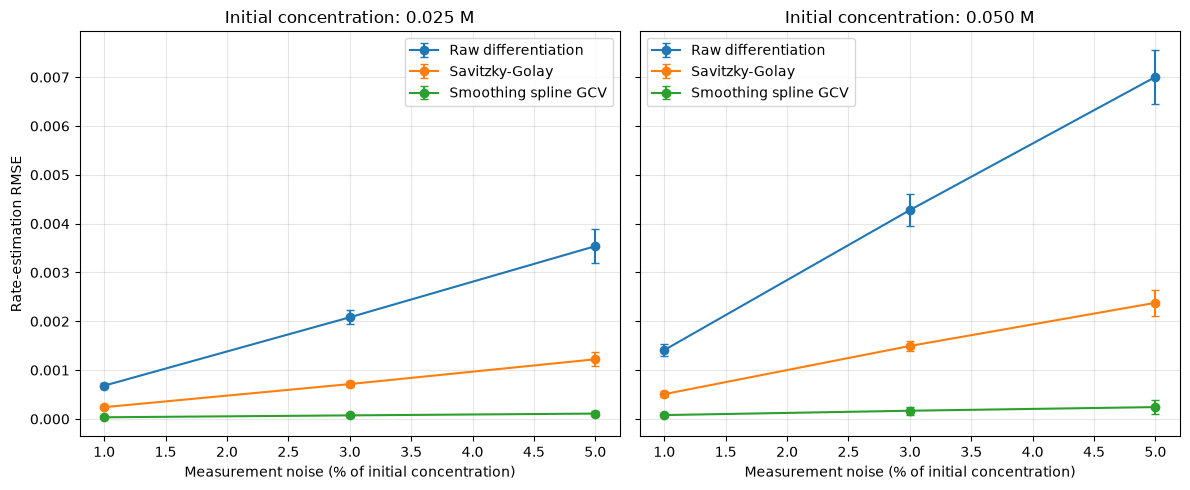

In [19]:
initial_concentrations = sorted(
    smooth_system_summary["Initial concentration"].unique()
)

fig, axes = plt.subplots(
    1, len(initial_concentrations),
    figsize=(6 * len(initial_concentrations), 5),
    sharey=True
)

for ax, ca0 in zip(np.atleast_1d(axes), initial_concentrations):
    for method in method_columns:
        subset = smooth_system_summary.loc[
            (smooth_system_summary["Initial concentration"] == ca0)
            & (smooth_system_summary["Method"] == method)
        ].sort_values("Noise")

        ax.errorbar(
            subset["Noise"] * 100,
            subset["Mean_RMSE"],
            yerr=subset["SD_RMSE"],
            marker="o",
            capsize=3,
            label=method
        )

    ax.set_title(f"Initial concentration: {ca0:.3f} M")
    ax.set_xlabel("Measurement noise (% of initial concentration)")
    ax.grid(alpha=0.3)
    ax.legend()

axes[0].set_ylabel("Rate-estimation RMSE")
plt.tight_layout()
plt.show()

## 13. Inspect a Representative Preprocessed Trajectory

The clean concentration is shown only as a visual evaluation reference. The three preprocessing methods receive the observed concentration alone.

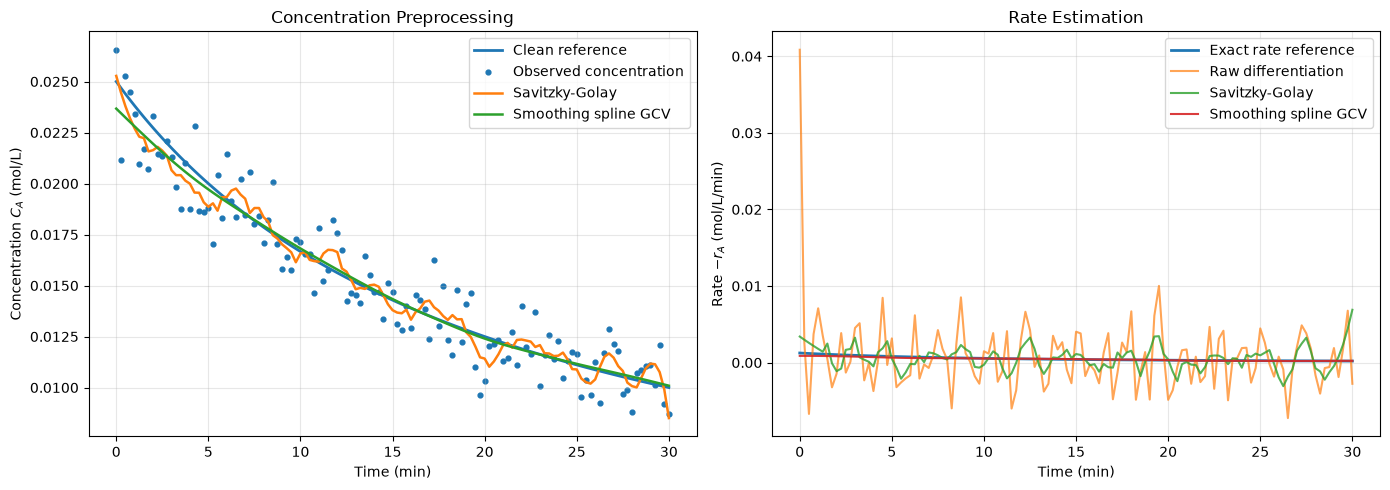

In [20]:
example_keys = {
    "reaction": "Second_Order",
    "initial_concentration_mol_L": TRAIN_INITIAL_CONCENTRATIONS[0],
    "noise_level": 0.05,
    "replicate": 1
}

example_processed = df_processed.loc[
    (df_processed["reaction"] == example_keys["reaction"])
    & (df_processed["initial_concentration_mol_L"] == example_keys["initial_concentration_mol_L"])
    & (df_processed["noise_level"] == example_keys["noise_level"])
    & (df_processed["replicate"] == example_keys["replicate"])
].copy()

example_truth = df.loc[
    (df["reaction"] == example_keys["reaction"])
    & (df["initial_concentration_mol_L"] == example_keys["initial_concentration_mol_L"])
    & (df["noise_level"] == example_keys["noise_level"])
    & (df["replicate"] == example_keys["replicate"]),
    ["time_min", "CA_true"]
]

example = example_processed.merge(
    example_truth,
    on="time_min",
    validate="one_to_one"
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    example["time_min"],
    example["CA_true"],
    label="Clean reference",
    linewidth=2
)
axes[0].scatter(
    example["time_min"],
    example["CA_observed"],
    label="Observed concentration",
    s=12
)
axes[0].plot(
    example["time_min"],
    example["CA_sg"],
    label="Savitzky-Golay",
    linewidth=1.8
)
axes[0].plot(
    example["time_min"],
    example["CA_spline"],
    label="Smoothing spline GCV",
    linewidth=1.8
)
axes[0].set_xlabel("Time (min)")
axes[0].set_ylabel("Concentration $C_A$ (mol/L)")
axes[0].set_title("Concentration Preprocessing")
axes[0].grid(alpha=0.3)
axes[0].legend()

example_rate = df_evaluation.loc[
    (df_evaluation["reaction"] == example_keys["reaction"])
    & (df_evaluation["initial_concentration_mol_L"] == example_keys["initial_concentration_mol_L"])
    & (df_evaluation["noise_level"] == example_keys["noise_level"])
    & (df_evaluation["replicate"] == example_keys["replicate"])
].copy()

axes[1].plot(
    example_rate["time_min"],
    example_rate["rate_true"],
    label="Exact rate reference",
    linewidth=2
)
axes[1].plot(
    example_rate["time_min"],
    example_rate["rate_raw"],
    label="Raw differentiation",
    alpha=0.7
)
axes[1].plot(
    example_rate["time_min"],
    example_rate["rate_sg"],
    label="Savitzky-Golay",
    alpha=0.8
)
axes[1].plot(
    example_rate["time_min"],
    example_rate["rate_spline"],
    label="Smoothing spline GCV",
    alpha=0.9
)
axes[1].set_xlabel("Time (min)")
axes[1].set_ylabel("Rate $-r_A$ (mol/L/min)")
axes[1].set_title("Rate Estimation")
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

## 14. Multi-Initial-Concentration PySR Discovery

PySR is trained on the two training initial concentrations. Replicate 5 at those same concentrations is used for equation selection through ODE trajectory reconstruction. The third initial concentration is excluded from preprocessing-method selection, PySR fitting, and candidate selection.

### 14.1 Define the Training and Validation Split

In [21]:
reaction = "Second_Order"
noise = 0.05
training_initial_concentrations = TRAIN_INITIAL_CONCENTRATIONS
test_initial_concentration = HELD_OUT_INITIAL_CONCENTRATION
training_replicates = [1, 2, 3, 4]
validation_replicate = 5

experiment = df_processed.loc[
    (df_processed["reaction"] == reaction)
    & (df_processed["noise_level"] == noise)
].copy()

train = experiment.loc[
    experiment["initial_concentration_mol_L"].isin(training_initial_concentrations)
    & experiment["replicate"].isin(training_replicates)
    & experiment["valid_interior"]
].copy()

validation_trajectories = experiment.loc[
    experiment["initial_concentration_mol_L"].isin(training_initial_concentrations)
    & (experiment["replicate"] == validation_replicate)
].copy()

test_trajectories = experiment.loc[
    experiment["initial_concentration_mol_L"] == test_initial_concentration
].copy()

print("Training observations:", len(train))
print("Validation trajectories:", validation_trajectories[["initial_concentration_mol_L", "replicate"]].drop_duplicates().shape[0])
print("Test trajectories:", test_trajectories["replicate"].nunique())
print("Training initial concentrations:", training_initial_concentrations)
print("Held-out initial concentration:", test_initial_concentration)

Training observations: 888
Validation trajectories: 2
Test trajectories: 5
Training initial concentrations: [0.025, 0.05]
Held-out initial concentration: 0.075


### 14.2 Train the Three PySR Models

In [22]:
method_columns = {
    "Raw": ("CA_observed", "rate_raw"),
    "Savitzky-Golay": ("CA_sg", "rate_sg"),
    "GCV": ("CA_spline", "rate_spline")
}

noisy_models = {}
training_data = {}

for method, (x_column, y_column) in method_columns.items():
    X_train = train[[x_column]].to_numpy(dtype=float)
    y_train = train[y_column].to_numpy(dtype=float)

    model = create_pysr_model(verbosity=0)
    model.fit(X_train, y_train)

    noisy_models[method] = model
    training_data[method] = (X_train, y_train)

    print(f"Completed: {method}")

Completed: Raw
Completed: Savitzky-Golay
Completed: GCV


### 14.3 Inspect the Discovered Equation Libraries

In [23]:
for method, model in noisy_models.items():
    print(f"\n{method} MODEL")
    display(
        model.equations_[
            ["complexity", "loss", "equation", "score"]
        ]
    )


Raw MODEL


,complexity,loss,equation,score
0,1,0.000029,0.0007948818,0.000000e+00
1,3,0.000029,x0 ^ 1.8198329,7.699141e-03
2,7,0.000029,(x0 ^ 0.840561) * (x0 * 1.0772427),3.655106e-07
3,9,0.000029,(((x0 ^ x0) + -0.9810054) * x0) * -0.7112725,1.909396e-05
4,11,0.000029,(x0 / ((x0 * (x0 / 0.015714718)) + 0.45431304)) * x0,1.542191e-05
5,13,0.000029,(x0 / ((0.0044733617 + ((x0 * x0) / 0.015714718)) + 0.45431304)) * x0,3.951287e-06
6,15,0.000029,x0 * (x0 / ((((x0 * x0) * (x0 + x0)) / 0.0023237662) + 0.49963355)),6.492711e-06
7,17,0.000029,x0 * (x0 / (((((x0 * 1.2123636) * x0) * (x0 + x0)) / 0.0023237662) + 0.49963355)),4.142846e-06



Savitzky-Golay MODEL


,complexity,loss,equation,score
0,1,0.000004,0.00080968434,0.000000
1,3,0.000003,x0 ^ 1.8042142,0.073808
2,5,0.000003,(x0 * 2.0035944) * x0,0.000924
3,7,0.000003,(x0 * (x0 * 2.0221324)) + -1.36144645e-5,0.000012
4,11,0.000003,(x0 * ((x0 + 1.8432789) * (x0 + 0.0036175582))) - 7.761227e-5,0.000001
5,13,0.000003,-2.0087391e-5 - ((x0 * x0) * (((x0 + -2.0633097) / x0) * x0)),0.000002



GCV MODEL


,complexity,loss,equation,score
0,1,5.281997e-07,0.0008137188,0.000000
1,3,3.453742e-08,x0 ^ 1.8097477,1.363716
2,5,3.392258e-08,(x0 ^ 1.8511679) * 1.1569009,0.008981
3,7,3.384882e-08,(x0 * (x0 ^ 0.86051077)) * 1.196707,0.001088
4,9,3.269542e-08,(((x0 + -0.95519817) * x0) + x0) + -0.00043685408,0.017335
5,11,3.260060e-08,(((x0 / (x0 - 0.1769076)) + 2.1696959) * x0) * x0,0.001452
6,15,3.152092e-08,x0 - (((x0 - ((x0 + (x0 ^ x0)) / -0.48760855)) * x0) - x0),0.008420
7,19,3.073102e-08,0.0002503522 - (((((x0 * x0) ^ x0) + x0) * (x0 * 0.96325994)) + (x0 * (x0 - 0.8918657))),0.006345


### 14.4 Define ODE-Based Candidate Evaluation

In [24]:
from scipy.integrate import solve_ivp


def integrate_symbolic_rate(expression, time, initial_concentration):
    rate_function = sp.lambdify(x0, expression, modules="numpy")
    concentration_grid = np.linspace(
        max(initial_concentration * 1e-5, 1e-10),
        initial_concentration,
        200
    )

    with np.errstate(all="ignore"):
        rates = np.asarray(rate_function(concentration_grid), dtype=float)

    if not np.all(np.isfinite(rates)) or np.any(rates < -1e-10):
        return None

    def rhs(_time, state):
        concentration = max(float(state[0]), 0.0)
        with np.errstate(all="ignore"):
            rate = float(rate_function(concentration))
        if not np.isfinite(rate) or rate < -1e-8:
            raise ValueError("Candidate gives a non-physical rate.")
        return [-max(rate, 0.0)]

    try:
        solution = solve_ivp(
            rhs,
            (float(time[0]), float(time[-1])),
            [float(initial_concentration)],
            t_eval=time,
            rtol=1e-7,
            atol=1e-10
        )
    except Exception:
        return None

    if not solution.success or solution.y.shape[1] != len(time):
        return None

    predictions = solution.y[0]
    if not np.all(np.isfinite(predictions)):
        return None

    return np.maximum(predictions, 0.0)


def evaluate_trajectory_library(model, trajectories):
    grouped_trajectories = [
        group.sort_values("time_min")
        for _, group in trajectories.groupby(
            ["initial_concentration_mol_L", "replicate"],
            sort=False
        )
    ]

    results = []

    for _, row in model.equations_.iterrows():
        expression = sp.factor(sp.cancel(sp.sympify(row["sympy_format"])))
        trajectory_errors = []

        for group in grouped_trajectories:
            time = group["time_min"].to_numpy(dtype=float)
            observed = group["CA_observed"].to_numpy(dtype=float)
            initial_concentration = float(observed[0])

            predictions = integrate_symbolic_rate(
                expression,
                time,
                initial_concentration
            )

            if predictions is None:
                trajectory_errors = []
                break

            trajectory_errors.append(
                np.sqrt(np.mean((observed - predictions) ** 2))
            )

        if not trajectory_errors:
            continue

        errors = np.asarray(trajectory_errors, dtype=float)
        results.append({
            "Equation": expression,
            "Complexity": int(row["complexity"]),
            "Training Loss": float(row["loss"]),
            "Mean Trajectory RMSE": float(errors.mean()),
            "SD Trajectory RMSE": float(errors.std(ddof=1)) if len(errors) > 1 else 0.0,
            "SE Trajectory RMSE": float(errors.std(ddof=1) / np.sqrt(len(errors))) if len(errors) > 1 else 0.0,
            "Validation Trajectories": len(errors)
        })

    return pd.DataFrame(results).sort_values(
        ["Mean Trajectory RMSE", "Complexity"]
    ).reset_index(drop=True)

### 14.5 Evaluate Candidate Equations on Validation Trajectories

In [25]:
validation_results = {}

for method, model in noisy_models.items():
    results = evaluate_trajectory_library(
        model,
        validation_trajectories
    )
    validation_results[method] = results

    print(f"\n{method} VALIDATION")
    display(results)


Raw VALIDATION


,Equation,Complexity,Training Loss,Mean Trajectory RMSE,SD Trajectory RMSE,SE Trajectory RMSE,Validation Trajectories
0,0.015714718*x0**2/(1.0*x0**2 + 0.00713940130732272),11,0.000029,0.002259,0.001068,0.000755,2
1,0.015714718*x0**2/(1.0*x0**2 + 0.00720969892495022),13,0.000029,0.002281,0.001085,0.000768,2
2,1.0772427*x0**1.840561,7,0.000029,0.002291,0.001046,0.000740,2
3,x0**1.8198329,3,0.000029,0.002296,0.001064,0.000753,2
4,0.0011618831*x0**2/(1.0*x0**3 + 0.000580515777938005),15,0.000029,0.002324,0.001051,0.000743,2
5,0.000958361913868084*x0**2/(1.0*x0**3 + 0.000478829765210705),17,0.000029,0.002370,0.001105,0.000781,2
6,0.000794881800000000,1,0.000029,0.010133,0.009644,0.006819,2



Savitzky-Golay VALIDATION


,Equation,Complexity,Training Loss,Mean Trajectory RMSE,SD Trajectory RMSE,SE Trajectory RMSE,Validation Trajectories
0,2.0035944*x0**2,5,0.000003,0.002170,0.000885,0.000626,2
1,x0**1.8042142,3,0.000003,0.002189,0.000962,0.000680,2
2,0.000809684340000000,1,0.000004,0.010091,0.009378,0.006631,2



GCV VALIDATION


,Equation,Complexity,Training Loss,Mean Trajectory RMSE,SD Trajectory RMSE,SE Trajectory RMSE,Validation Trajectories
0,1.196707*x0**1.86051077,7,3.384882e-08,0.002202,0.000974,0.000688,2
1,1.1569009*x0**1.8511679,5,3.392258e-08,0.002205,0.000979,0.000693,2
2,-1.96325994*(1.0*x0**2 + 0.490643098437592*x0*(x0**2)**x0 - 0.454277949561789*x0 - 0.000127518620891332),19,3.073102e-08,0.002207,0.000989,0.000699,2
3,3.1696959*x0**2*(1.0*x0 - 0.121095432025148)/(1.0*x0 - 0.1769076),11,3.260060e-08,0.002212,0.000977,0.000691,2
4,x0**1.8097477,3,3.453742e-08,0.002214,0.000996,0.000704,2
5,0.000813718800000000,1,5.281997e-07,0.010081,0.009304,0.006579,2


### 14.6 Select a Compact Candidate Using the One-Standard-Error Rule

In [26]:
selected_candidates = {}
selection_rows = []

for method, results in validation_results.items():
    if results.empty:
        continue

    best = results.iloc[0]
    threshold = (
        best["Mean Trajectory RMSE"]
        + best["SE Trajectory RMSE"]
    )

    eligible = results.loc[
        results["Mean Trajectory RMSE"] <= threshold
    ].sort_values(
        ["Complexity", "Mean Trajectory RMSE", "Training Loss"]
    )

    selected = eligible.iloc[0]
    selected_candidates[method] = selected["Equation"]

    selection_rows.append({
        "Method": method,
        "Selected Equation": selected["Equation"],
        "Complexity": selected["Complexity"],
        "Validation Trajectory RMSE": selected["Mean Trajectory RMSE"],
        "Best Candidate RMSE": best["Mean Trajectory RMSE"],
        "One-SE Threshold": threshold
    })

selection_df = pd.DataFrame(selection_rows).sort_values(
    ["Validation Trajectory RMSE", "Complexity"]
).reset_index(drop=True)

display(selection_df)

if selection_df.empty:
    raise RuntimeError("No physically valid PySR candidate could be integrated.")

selected_method = selection_df.iloc[0]["Method"]
selected_equation = selected_candidates[selected_method]

print("Selected preprocessing method:", selected_method)
print("Selected equation:", selected_equation)

,Method,Selected Equation,Complexity,Validation Trajectory RMSE,Best Candidate RMSE,One-SE Threshold
0,Savitzky-Golay,x0**1.8042142,3,0.002189,0.002170,0.002795
1,GCV,x0**1.8097477,3,0.002214,0.002202,0.002890
2,Raw,x0**1.8198329,3,0.002296,0.002259,0.003014


Selected preprocessing method: Savitzky-Golay
Selected equation: x0**1.8042142


## 15. Final Test on an Unseen Initial Concentration

The held-out initial concentration is not used for training or candidate selection. It is evaluated only after the preprocessing method and equation have been selected using the training conditions.

### 15.1 Evaluate the Selected Equation on the Held-Out Condition

In [27]:
test_reference = df.loc[
    (df["reaction"] == reaction)
    & (df["noise_level"] == noise)
    & (df["initial_concentration_mol_L"] == test_initial_concentration),
    ["reaction", "initial_concentration_mol_L", "noise_level", "replicate", "time_min", "CA_true"]
]

test_eval = test_trajectories.merge(
    test_reference,
    on=["reaction", "initial_concentration_mol_L", "noise_level", "replicate", "time_min"],
    how="inner",
    validate="one_to_one"
)

test_results = []

for replicate, group in test_eval.groupby("replicate", sort=True):
    group = group.sort_values("time_min")
    time = group["time_min"].to_numpy(dtype=float)
    observed = group["CA_observed"].to_numpy(dtype=float)
    true_concentration = group["CA_true"].to_numpy(dtype=float)

    predictions = integrate_symbolic_rate(
        selected_equation,
        time,
        float(observed[0])
    )

    if predictions is None:
        continue

    test_results.append({
        "Replicate": int(replicate),
        "Observed RMSE": float(np.sqrt(np.mean((observed - predictions) ** 2))),
        "Retrospective Clean RMSE": float(np.sqrt(np.mean((true_concentration - predictions) ** 2)))
    })

test_results_df = pd.DataFrame(test_results)
display(test_results_df)

print("Selected method:", selected_method)
print("Selected equation:", selected_equation)
print("Mean observed-data RMSE:", test_results_df["Observed RMSE"].mean())
print("Mean retrospective clean-data RMSE:", test_results_df["Retrospective Clean RMSE"].mean())

,Replicate,Observed RMSE,Retrospective Clean RMSE
0,1,0.004807,0.002804
1,2,0.004307,0.002489
2,3,0.004535,0.002158
3,4,0.004136,0.001388
4,5,0.003705,0.000791


Selected method: Savitzky-Golay
Selected equation: x0**1.8042142
Mean observed-data RMSE: 0.004297951800364034
Mean retrospective clean-data RMSE: 0.0019258897919723693


### 15.2 Plot the Held-Out Trajectory

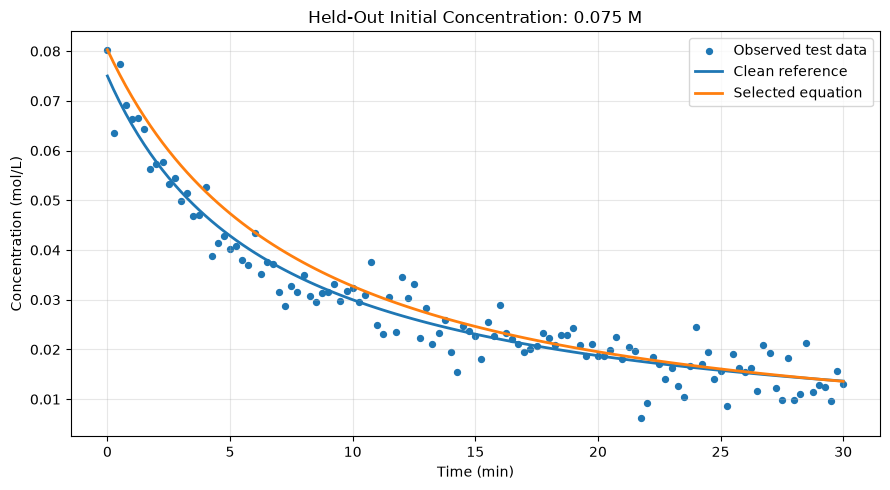

In [28]:
plot_group = test_eval.loc[
    test_eval["replicate"] == test_eval["replicate"].min()
].sort_values("time_min")

plot_time = plot_group["time_min"].to_numpy(dtype=float)
plot_observed = plot_group["CA_observed"].to_numpy(dtype=float)
plot_true = plot_group["CA_true"].to_numpy(dtype=float)
plot_prediction = integrate_symbolic_rate(
    selected_equation,
    plot_time,
    float(plot_observed[0])
)

plt.figure(figsize=(9, 5))
plt.scatter(plot_time, plot_observed, s=18, label="Observed test data")
plt.plot(plot_time, plot_true, linewidth=2, label="Clean reference")
plt.plot(plot_time, plot_prediction, linewidth=2, label="Selected equation")
plt.xlabel("Time (min)")
plt.ylabel("Concentration (mol/L)")
plt.title(f"Held-Out Initial Concentration: {test_initial_concentration:.3f} M")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 16. Scope of the Current Discovery Result

This run evaluates second-order kinetics at 5% noise. Training uses 0.025 M and 0.050 M; 0.075 M is held out for final testing. The 0.050 M condition was used in earlier exploratory runs, so it is retained in training rather than reused as the final test. The clean-data baseline and preprocessing-method comparison use only the training initial concentrations. The current run is a controlled generalization experiment, not yet a general-purpose model for all six rate laws and all noise levels.

## 17. Export and Use a CA-Only Rate Law

The clean-data PySR baseline recovered the first-order law as 0.1 × CA with near-zero training error. The noisy held-out trajectory experiment at the end of this notebook covers second-order kinetics at 5% noise, not first-order kinetics. In that noisy experiment, Savitzky–Golay was selected using held-out trajectory reconstruction and a one-standard-error rule; this is the reference for the site method preference, not proof of first-order noisy-data accuracy.

The upload pipeline in `rate_law_discovery.py` compares raw differentiation, Savitzky–Golay, and GCV spline inputs; fits a separate one-variable PySR search for each; refits coefficients and tests simplified candidates by ODE reconstruction of held-out trajectories. When methods fall within the validation one-standard-error band, the site prefers Savitzky–Golay. With one run, it uses a disclosed 5% tie window; with multiple runs, it reserves complete trajectories. The final equation remains a function of `CA` only.

The Streamlit front end is `app.py`. Use `requirements.txt` and the README for setup, input format, and interpretation. The notebook example below shows how to invoke the same discovery and JSON-export functions for a new CSV.


In [ ]:
# Example for a new experiment CSV. Run after installing requirements.txt and Julia.
from rate_law_discovery import discover_rate_law, export_result

uploaded_data = pd.read_csv("my_experiment.csv")  # columns: time_min, CA; optional run_id
result = discover_rate_law(
    uploaded_data,
    time_col="time_min",
    ca_col="CA",
    trajectory_col="run_id" if "run_id" in uploaded_data.columns else None,
)
display(result.to_dict())
export_result(result, "model_exports/my_experiment_rate_law.json")
